In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train_df=pd.read_csv("C:/Users/MAREY/Downloads/archive (1)/customer_churn_dataset-training-master.csv")

In [3]:
train_df.head(5)

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [4]:
train_df.shape

(440833, 12)

In [5]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440833 entries, 0 to 440832
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         440832 non-null  float64
 1   Age                440832 non-null  float64
 2   Gender             440832 non-null  object 
 3   Tenure             440832 non-null  float64
 4   Usage Frequency    440832 non-null  float64
 5   Support Calls      440832 non-null  float64
 6   Payment Delay      440832 non-null  float64
 7   Subscription Type  440832 non-null  object 
 8   Contract Length    440832 non-null  object 
 9   Total Spend        440832 non-null  float64
 10  Last Interaction   440832 non-null  float64
 11  Churn              440832 non-null  float64
dtypes: float64(9), object(3)
memory usage: 40.4+ MB


In [6]:
train_df.isnull().sum()

CustomerID           1
Age                  1
Gender               1
Tenure               1
Usage Frequency      1
Support Calls        1
Payment Delay        1
Subscription Type    1
Contract Length      1
Total Spend          1
Last Interaction     1
Churn                1
dtype: int64

In [7]:
train_df.dropna(inplace=True)

In [8]:
train_df.isnull().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [9]:
train_df.shape

(440832, 12)

In [10]:
train_df.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000
mean,225398.667955,39.373153,31.256336,15.807494,3.604437,12.965722,631.616223,14.480868,0.567107
std,129531.918550,12.442369,17.255727,8.586242,3.070218,8.258063,240.803001,8.596208,0.495477
min,2.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,113621.750000,29.000000,16.000000,9.000000,1.000000,6.000000,480.000000,7.000000,0.000000
50%,226125.500000,39.000000,32.000000,16.000000,3.000000,12.000000,661.000000,14.000000,1.000000
75%,337739.250000,48.000000,46.000000,23.000000,6.000000,19.000000,830.000000,22.000000,1.000000
max,449999.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [11]:
object_cols = train_df.select_dtypes(include="object").columns
num_cols=train_df.select_dtypes(include=['float','int']).columns

In [12]:
num_cols=num_cols.drop(['CustomerID','Churn'])

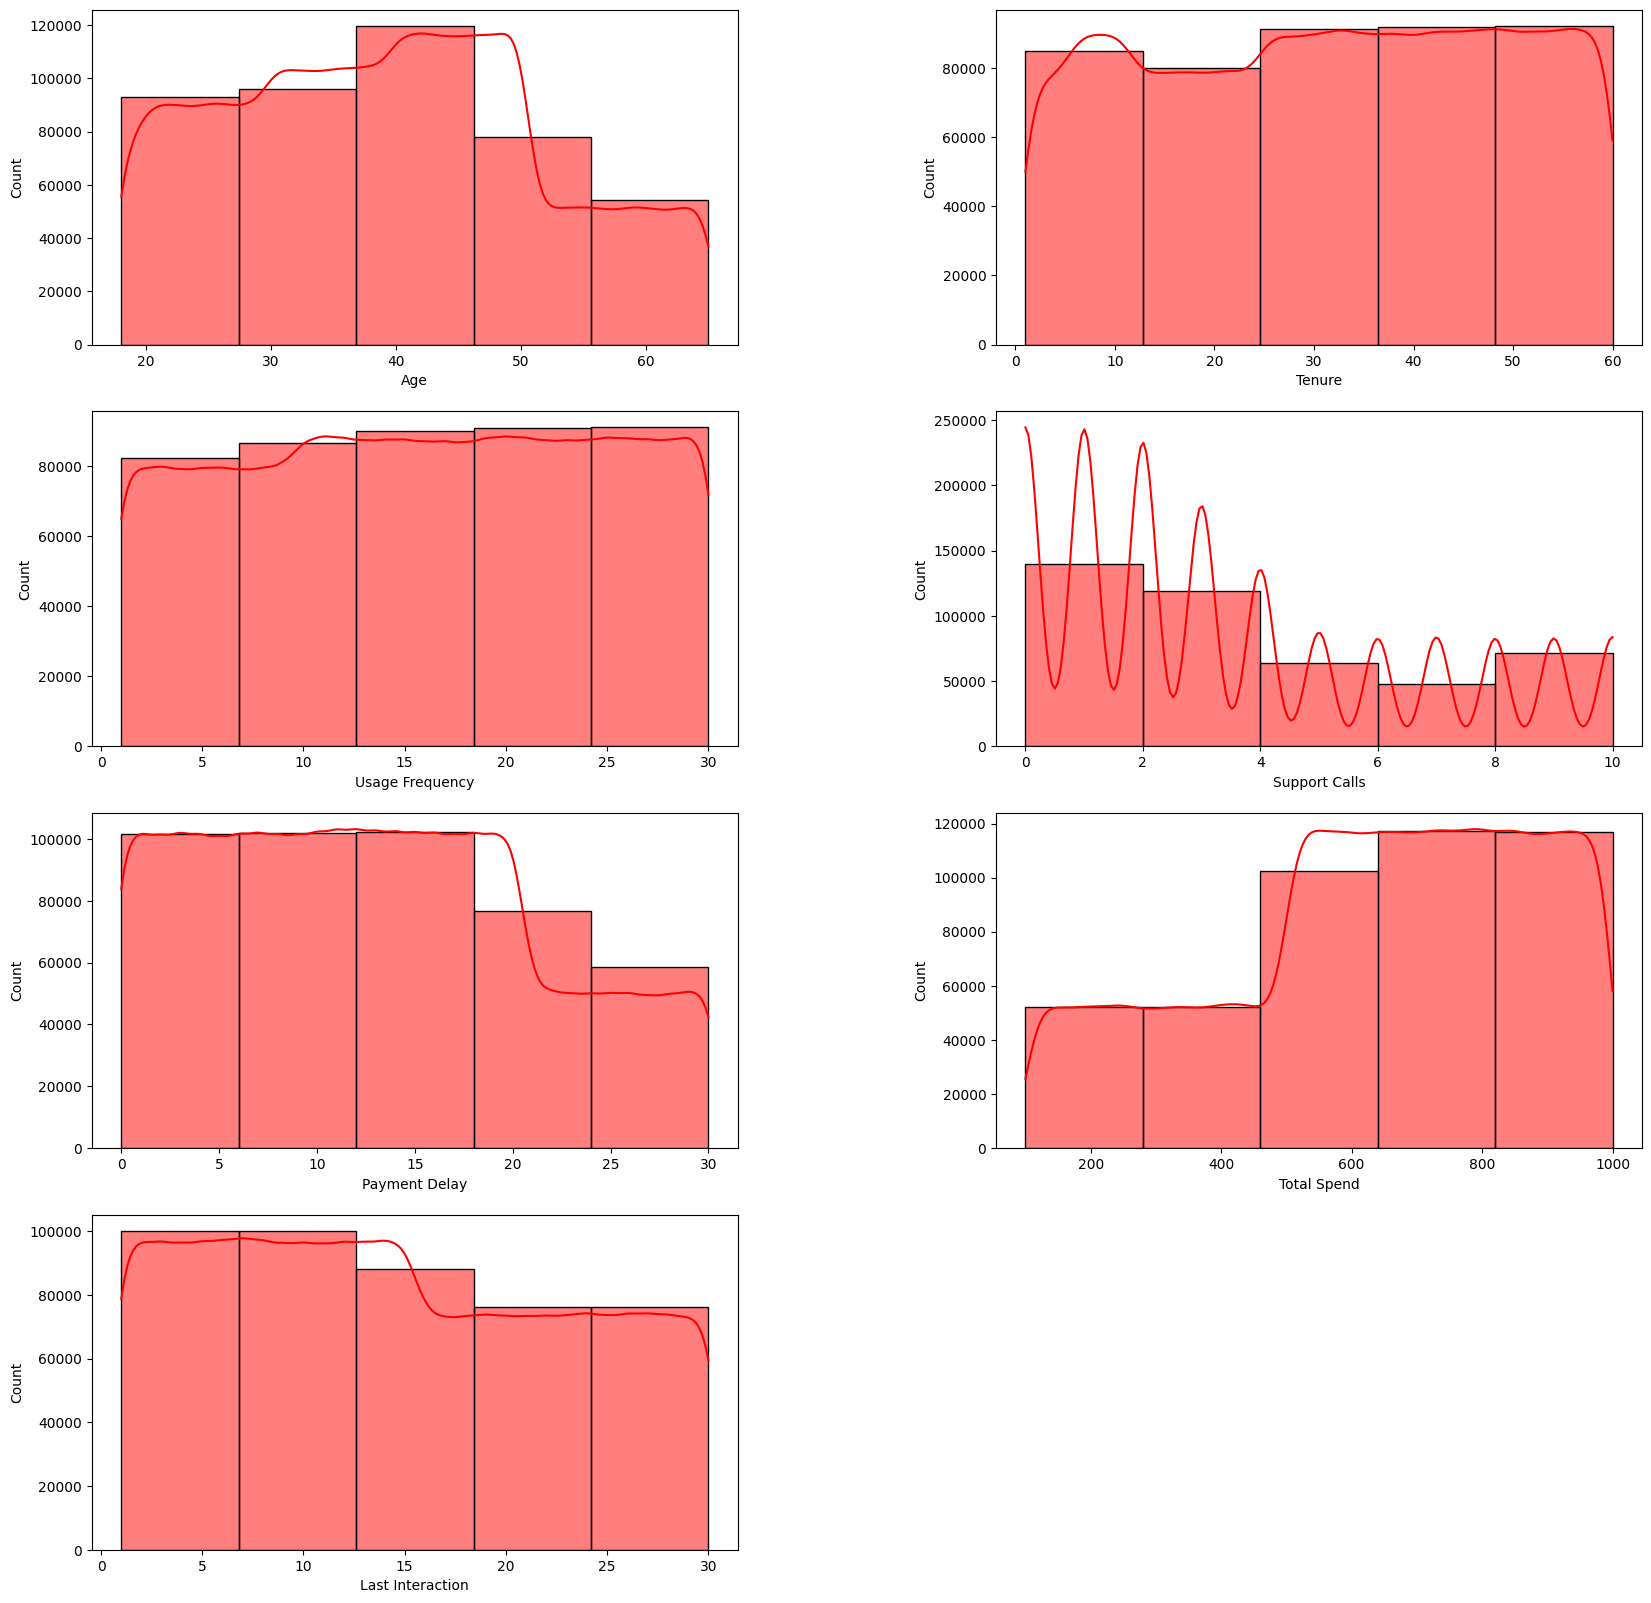

In [13]:
plt.figure(figsize=(20, 20))
for i, col in enumerate(num_cols, start=1):
    plt.subplot(4 , 2,i)
    plt.subplots_adjust(wspace = 0.4 ,hspace = 0.2)
    sns.histplot(train_df[col] , kde = True , bins = 5,color = "red")
plt.show()


In [14]:
cats_cols1 = train_df[["Gender" , "Subscription Type" , "Contract Length" , "Churn"]]

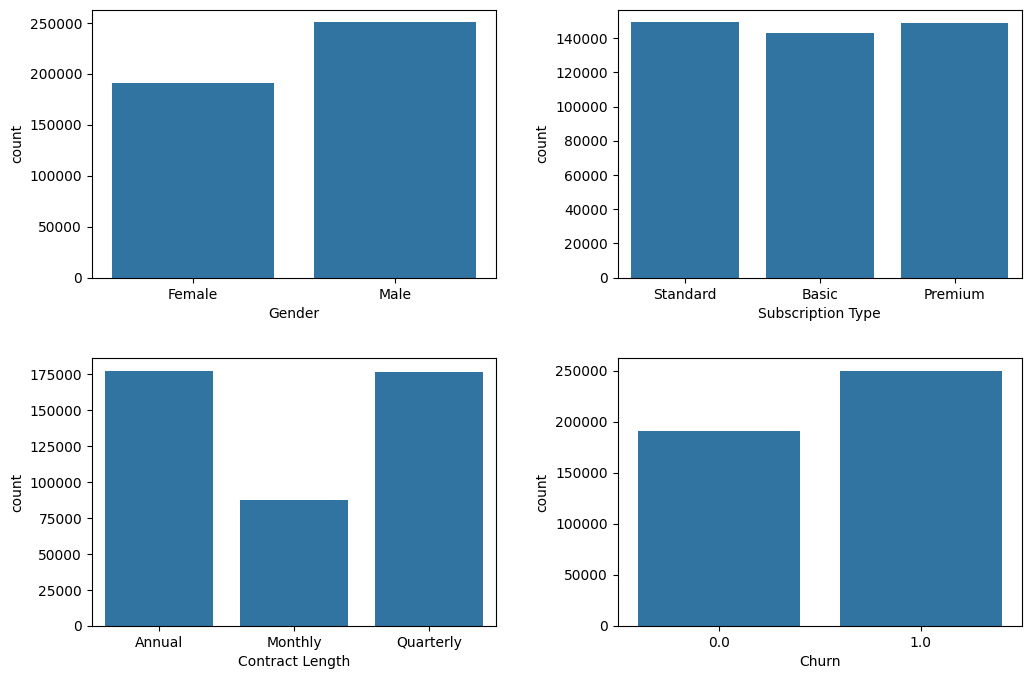

In [15]:
plt.figure(figsize= (12,8))
for i,col in enumerate(cats_cols1,start=1):
    plt.subplots_adjust(hspace = 0.3 , wspace = 0.3)
    plt.subplot(2,2,i)
    sns.countplot(x=train_df[col])
plt.show()

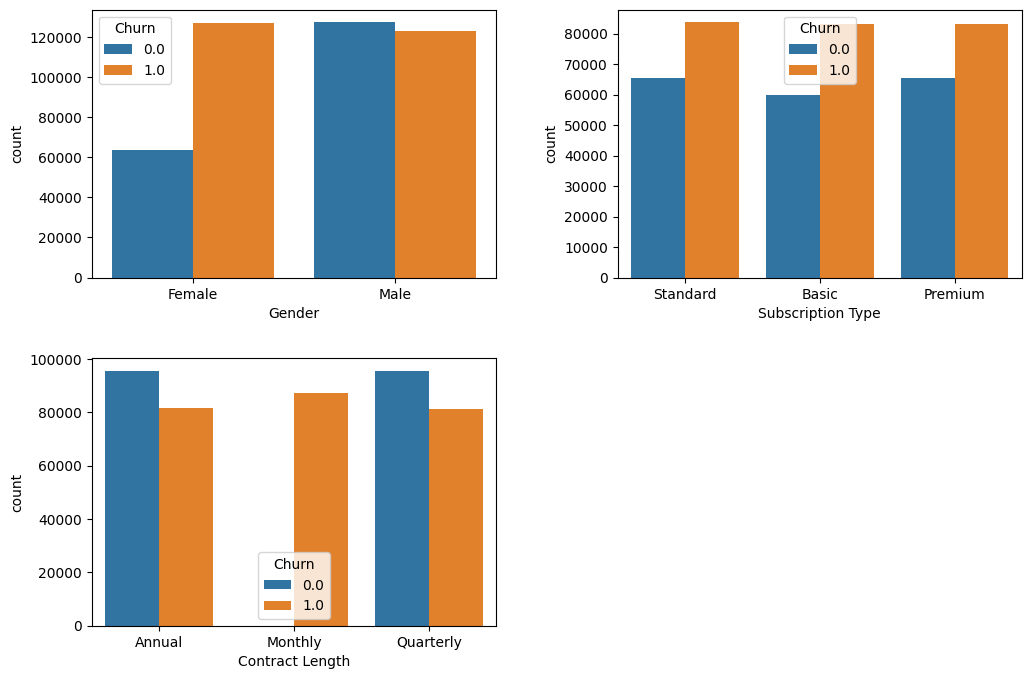

In [16]:
plt.figure(figsize= (12,8))
for i,col in enumerate(cats_cols1.drop(columns = "Churn"),start=1):
    plt.subplots_adjust(hspace = 0.3 , wspace = 0.3)
    plt.subplot(2,2,i)
    sns.countplot(x=train_df[col],hue='Churn',data=train_df)
plt.show()

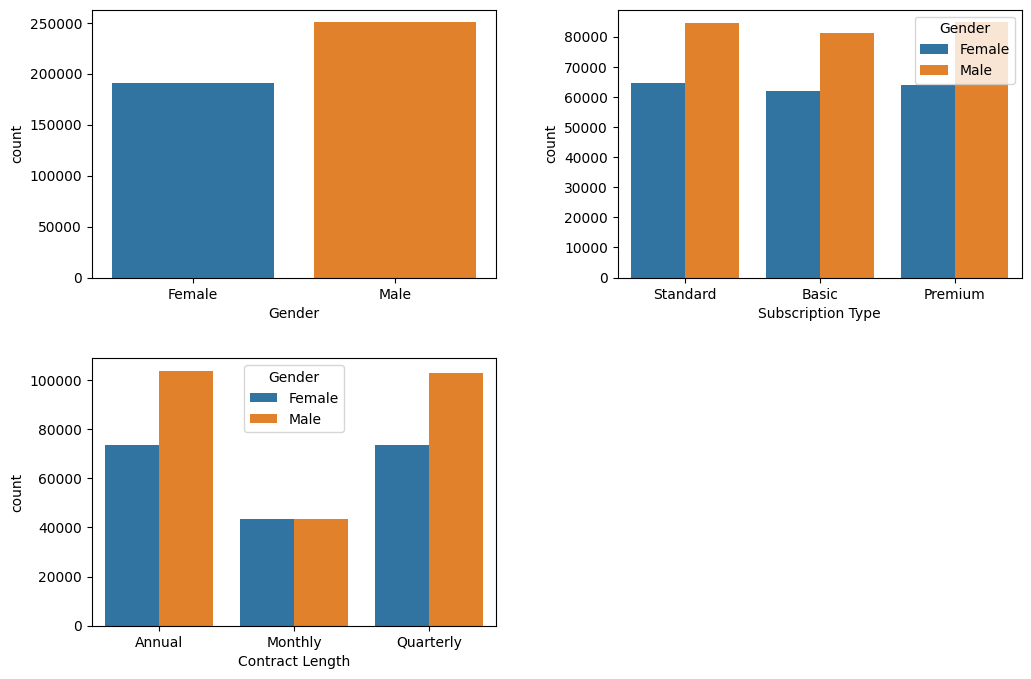

In [17]:
plt.figure(figsize= (12,8))
for i,col in enumerate(cats_cols1.drop(columns = "Churn"),start=1):
    plt.subplots_adjust(hspace = 0.3 , wspace = 0.3)
    plt.subplot(2,2,i)
    sns.countplot(x=train_df[col],hue='Gender',data=train_df)
plt.show()

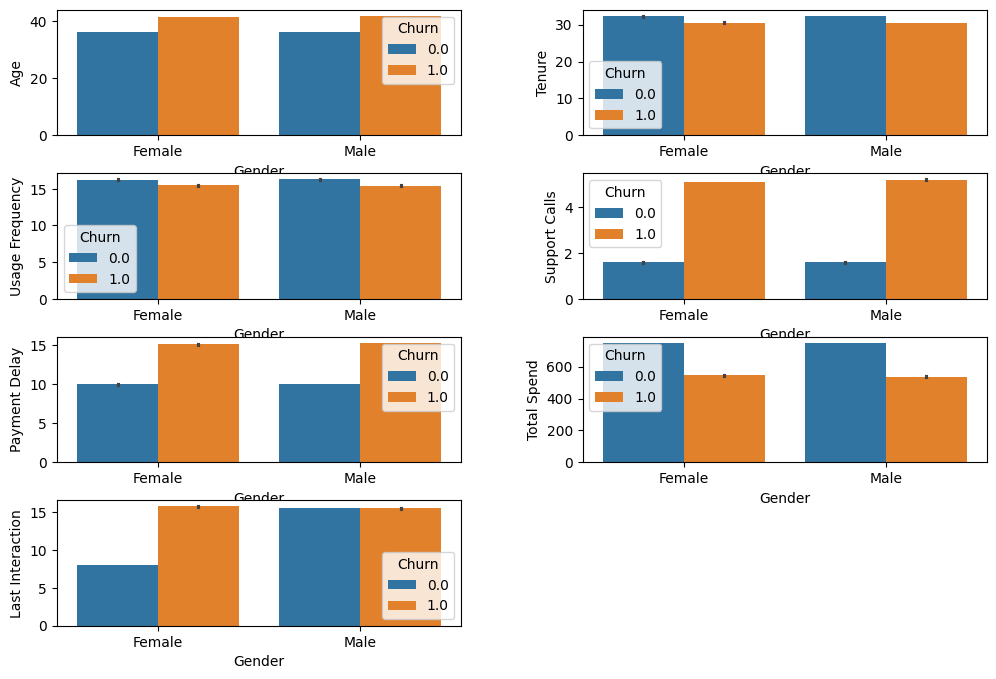

In [18]:
plt.figure(figsize= (12,8))
for i , cols in enumerate(num_cols.drop(["Churn", "CustomerID"],errors="ignore") , 1):
    plt.subplot(4 , 2 ,i)
    plt.subplots_adjust(hspace = 0.3 , wspace = 0.3)
    sns.barplot(y= train_df[cols] ,x= "Gender" ,hue = "Churn" , data = train_df )
plt.show()

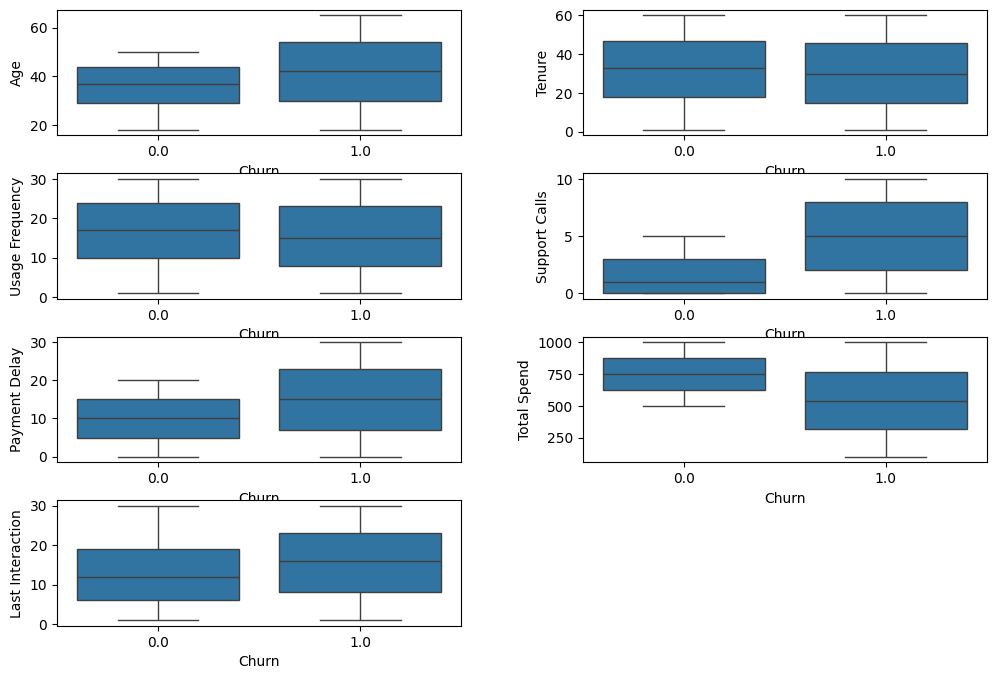

In [19]:
plt.figure(figsize= (12,8))
for i , cols in enumerate(num_cols , 1):
    plt.subplot(4 , 2 ,i)
    plt.subplots_adjust(hspace = 0.3 , wspace = 0.3)
    sns.boxplot(y= train_df[cols] ,x= "Churn"  , data = train_df )
plt.show()

In [20]:
from sklearn.preprocessing import OrdinalEncoder

In [21]:
oe=OrdinalEncoder()

In [22]:
train_df.dtypes

CustomerID           float64
Age                  float64
Gender                object
Tenure               float64
Usage Frequency      float64
Support Calls        float64
Payment Delay        float64
Subscription Type     object
Contract Length       object
Total Spend          float64
Last Interaction     float64
Churn                float64
dtype: object

In [23]:
object_cols

Index(['Gender', 'Subscription Type', 'Contract Length'], dtype='object')

In [24]:
train_df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [25]:
train_df

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.00,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.00,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.00,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.00,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.00,20.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
440828,449995.0,42.0,Male,54.0,15.0,1.0,3.0,Premium,Annual,716.38,8.0,0.0
440829,449996.0,25.0,Female,8.0,13.0,1.0,20.0,Premium,Annual,745.38,2.0,0.0
440830,449997.0,26.0,Male,35.0,27.0,1.0,5.0,Standard,Quarterly,977.31,9.0,0.0
440831,449998.0,28.0,Male,55.0,14.0,2.0,0.0,Standard,Quarterly,602.55,2.0,0.0


In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [27]:
x=train_df.drop(columns='Churn')
y=train_df['Churn']

In [28]:
x_train,x_val,y_train,y_val=train_test_split(x,y,test_size=.2,random_state=42)

In [29]:
x_train[object_cols] = oe.fit_transform(x_train[object_cols])
x_val[object_cols] = oe.transform(x_val[object_cols])

In [30]:
x_train.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction
321745,328860.0,24.0,1.0,58.0,28.0,0.0,4.0,0.0,0.0,665.22,29.0
175119,179930.0,24.0,1.0,26.0,12.0,1.0,26.0,0.0,2.0,754.00,12.0
272448,279562.0,18.0,1.0,36.0,8.0,0.0,7.0,1.0,2.0,852.86,9.0
66769,68280.0,36.0,0.0,18.0,9.0,2.0,23.0,1.0,1.0,758.00,3.0
70297,71967.0,57.0,0.0,27.0,26.0,8.0,15.0,0.0,1.0,688.00,10.0


In [31]:
from sklearn.preprocessing import StandardScaler
num_cols = ["CustomerID","Age", "Tenure", "Usage Frequency", "Support Calls",
            "Payment Delay", "Total Spend", "Last Interaction"]   # no CustomerID

ss = StandardScaler()
x_train[num_cols] = ss.fit_transform(x_train[num_cols])
x_val[num_cols]   = ss.transform(x_val[num_cols])

In [32]:
x_train.head(5)

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction
321745,0.799347,-1.234718,1.0,1.550094,1.419341,-1.173301,-1.086163,0.0,0.0,0.139639,1.689759
175119,-0.350505,-1.234718,1.0,-0.305269,-0.443767,-0.847672,1.578104,0.0,2.0,0.508215,-0.287785
272448,0.418729,-1.716941,1.0,0.274532,-0.909544,-1.173301,-0.722854,1.0,2.0,0.918640,-0.636763
66769,-1.212527,-0.270271,0.0,-0.769110,-0.793100,-0.522042,1.214794,1.0,1.0,0.524821,-1.334720
70297,-1.184061,1.417510,0.0,-0.247289,1.186452,1.431737,0.245970,0.0,1.0,0.234211,-0.520437


Evaluting the model

In [33]:
print(x_train.shape,x_val.shape)

(352665, 11) (88167, 11)


In [34]:
model_log=LogisticRegression()

In [35]:
model_log.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [36]:
y_pred=model_log.predict(x_val)
x_pred=model_log.predict(x_train)

In [37]:
print("validation_Accuracy: " ,accuracy_score(y_val,y_pred))
print("training_Accuracy: " ,accuracy_score(y_train,x_pred))

validation_Accuracy:  0.9775426179863214
training_Accuracy:  0.9775877957835339


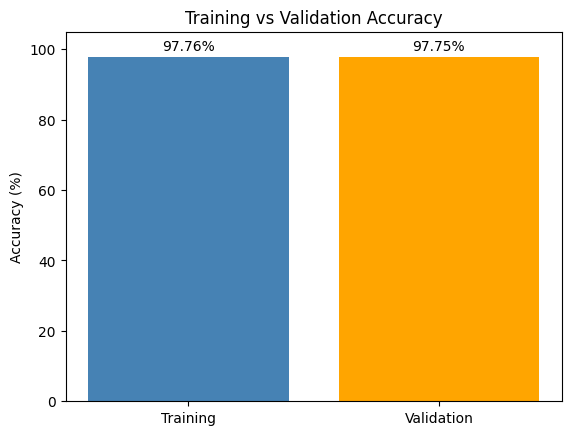

In [38]:
train_acc = accuracy_score(y_train, x_pred)
val_acc = accuracy_score(y_val, y_pred)

bars = plt.bar(
    ["Training", "Validation"],
    [train_acc * 100, val_acc * 100],
    color=["steelblue", "orange"]
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.ylim(0, 105)
plt.show()

In [39]:
#### now let's evalute our test data
test_df=pd.read_csv("C:/Users/MAREY/Downloads/archive (1)/customer_churn_dataset-testing-master.csv")

In [40]:
test_df.shape

(64374, 12)

In [41]:
test_df.isnull().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [42]:
test_df.duplicated().sum()

np.int64(0)

In [43]:
test_df.dtypes

CustomerID            int64
Age                   int64
Gender               object
Tenure                int64
Usage Frequency       int64
Support Calls         int64
Payment Delay         int64
Subscription Type    object
Contract Length      object
Total Spend           int64
Last Interaction      int64
Churn                 int64
dtype: object

In [44]:
test_catcol=test_df.select_dtypes(include=["object", "category"]).columns

In [45]:
test_df[test_catcol]=oe.transform(test_df[test_catcol])

In [46]:
test_df.dtypes

CustomerID             int64
Age                    int64
Gender               float64
Tenure                 int64
Usage Frequency        int64
Support Calls          int64
Payment Delay          int64
Subscription Type    float64
Contract Length      float64
Total Spend            int64
Last Interaction       int64
Churn                  int64
dtype: object

In [47]:
test_df.head(5)

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,0.0,25,14,4,27,0.0,1.0,598,9,1
1,2,41,0.0,28,28,7,13,2.0,1.0,584,20,0
2,3,47,1.0,27,10,2,29,1.0,0.0,757,21,0
3,4,35,1.0,9,12,5,17,1.0,2.0,232,18,0
4,5,53,0.0,58,24,9,2,2.0,0.0,533,18,0


In [48]:
test_x=test_df.drop(columns='Churn')
test_y=test_df['Churn']

In [49]:
test_x[num_cols] = ss.transform(test_x[num_cols])


In [50]:
test_x

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction
0,-1.739692,-1.395459,0.0,-0.363250,-0.210879,0.129218,1.699207,0.0,1.0,-0.139430,-0.636763
1,-1.739685,0.131581,0.0,-0.189309,1.419341,1.106107,0.003764,2.0,1.0,-0.197552,0.642824
2,-1.739677,0.613805,1.0,-0.247289,-0.676656,-0.522042,1.941413,1.0,0.0,0.520670,0.759150
3,-1.739669,-0.350642,1.0,-1.290931,-0.443767,0.454848,0.488176,1.0,2.0,-1.658906,0.410172
4,-1.739661,1.096028,0.0,1.550094,0.953564,1.757367,-1.328370,2.0,0.0,-0.409282,0.410172
...,...,...,...,...,...,...,...,...,...,...,...
64369,-1.242715,0.453063,0.0,0.100591,-0.443767,0.780477,0.972588,0.0,2.0,1.309469,-0.055133
64370,-1.242707,-0.189901,1.0,-1.464872,-1.724654,0.454848,1.093691,2.0,0.0,1.209831,-0.636763
64371,-1.242700,-1.154348,1.0,0.448472,-0.210879,1.431737,2.062516,1.0,1.0,-1.264506,0.642824
64372,-1.242692,0.854916,0.0,-0.769110,0.371342,1.106107,1.093691,2.0,1.0,-0.380221,-0.171459
